# 7. Benzene: MOs and Symmetry

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4/blob/main/book/07-Benzene/071-Benzene.ipynb)
:::

Benzene is the **iconic** organic molecule. Imagine if I had to design a superhero outfit for "Chemistry Man" (He can change phase from solid to liquid, but he requires a heat source to do so). I would choose a **hexagon**, representing the planar benzene structure, as the superhero **symbol** emblazoned on the cape.

We have already created a **molecular orbital diagram** for the &pi;-system of benzene using SHMO theory. Let us now **repeat** that exercise using *Psi4*.

## Learning Goals

In this exercise, we will accomplish the following…

1.	Use *Python* to **build** benzene. We will use the **symmetry** of the *D<sub>6h</sub>* point group to place the atoms, and see which part of that symmetry *Psi4* can actually use.
2.	We will then **optimize** the structure and **visualize** the orbitals.
3.	This will be a good system to demonstrate the benefits of symmetry. We will try **expensive** energy calculations using *D<sub>2h</sub>*, *C<sub>2v</sub>*, *C<sub>2h</sub>* and *C<sub>1</sub>* symmetry and see what it costs us (and learn that the answer depends on the **method**).

In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install packages only if needed
# Google Colab does not include every Python package
#
# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:                  # if the package exists import it, otherwise install it
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot style sheets from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/S2_classic2.mplstyle

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    plt.style.use("../../styles/tufte.mplstyle")

## Setting Up the Notebook

As always, the first code cell of the notebook (hidden on this web page) **imports** *Psi4*, *py3Dmol*, *NumPy*, *pandas* and *Matplotlib* and applies the plot **style sheet**. See [Chapter 2](../02-SmallMolecules/021-SmallMolecules.ipynb) for the details.

```{admonition} Running this notebook in Google Colab
:class: dropdown
The first code cell checks whether the notebook is running in *Google Colab*. If it is, the cell **installs** *Psi4* for you. *Colab* does not come with *conda*, so the cell first installs it using a package called *condacolab*. This **restarts** the *Colab* session. When it has restarted, simply **run the first cell again**. It will then install *Psi4* with *conda* (*Psi4* cannot be installed with *pip*), install *py3Dmol* with *pip*, and download the plot style sheets from the book's *GitHub* repository. This takes a few minutes, and you must do it every time you start a new *Colab* session. On your own computer, the cell just imports the packages.
```

Next, we tell *Psi4* how much of the computer it may use and set a few options.

In [2]:
psi4.set_memory("4 GB")
psi4.set_num_threads(4)

psi4.set_options({"puream": False,
                  "cubic_grid_spacing": [0.4, 0.4, 0.4],
                  "cubic_grid_overage": [4.0, 4.0, 4.0]})


  Memory set to   3.725 GiB by Python driver.
  Threads set to 4 by Python driver.


| Line | Notes |
| :---- | :---- |
| `"puream": False` | Use **Cartesian** *d*- and *f*-functions, as *GAMESS* does by default (see [Chapter 6](../06-PiOrbitals/061-PiOrbitals.ipynb)). This way our big basis set below will have exactly the **same number** of atomic orbitals as the one in the *GAMESS* book. |
| `cubic_grid_overage` | A little more empty space around the molecule (4 Bohr) than in the last chapter, because benzene's &pi;-orbitals stick out above and below the ring. |

This time we do **not** set `scf_type`. *Psi4* will use its default, a fast **density-fitted** (DF) algorithm, for the Hartree-Fock and DFT calculations. That choice will matter when we talk about timing.

### Some Helpful Tools

We will reuse our **tools** from the previous chapters and add one more. The cell is hidden on the web page but you can expand it to see the code.

In [3]:
def show_molecule(mol):
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

def bond_length(mol, i, j):
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms
    return np.linalg.norm(xyz[i] - xyz[j])

def bond_angle(mol, i, j, k):
    xyz = mol.geometry().np
    a = xyz[i] - xyz[j]
    b = xyz[k] - xyz[j]
    cos_angle = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.degrees(np.arccos(cos_angle))

def plot_history(history, title):
    energies = np.array(history["energy"])
    delta_E = (energies - energies[-1]) * psi4.constants.hartree2kJmol
    steps = np.arange(1, len(energies) + 1)

    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
    ax.plot(steps, delta_E, color="black", linewidth=0.7, marker="o",
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
    ax.set_xticks(steps)
    ax.set_xlabel("Optimization step")
    ax.set_ylabel(r"$E - E_{final}$ (kJ/mol)")
    ax.set_title(title)
    plt.show()

def search_file(filename, text):
    with open(filename) as f:
        for number, line in enumerate(f, start=1):
            if text.lower() in line.lower():
                print(f"{number:6d}: {line.rstrip()}")

def show_orbital(mol, cube_file, isoval=0.05):
    with open(cube_file) as f:
        cube = f.read()
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.addVolumetricData(cube, "cube", {"isoval": isoval, "color": "#FFB3BA", "opacity": 0.85})
    view.addVolumetricData(cube, "cube", {"isoval": -isoval, "color": "#AEC6CF", "opacity": 0.85})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

def show_density_esp(mol, density_file, esp_file, esp_min, esp_max, isoval=0.002):
    with open(density_file) as f:
        density = f.read()
    with open(esp_file) as f:
        esp = f.read()
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.addVolumetricData(density, "cube", {"isoval": isoval, "opacity": 0.9,
                                             "voldata": esp, "volformat": "cube",
                                             "volscheme": {"gradient": "rwb",
                                                           "min": esp_min, "max": esp_max}})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

def cube_values(cube_file):
    with open(cube_file) as f:
        lines = f.readlines()
    n_atoms = abs(int(lines[2].split()[0]))
    numbers = " ".join(lines[6 + n_atoms:]).split()
    return np.array(numbers, dtype=float)

def orbital_table(wfn, mol):
    labels = mol.irrep_labels()
    eps_by_irrep = wfn.epsilon_a().nph
    orbital_list = []
    for h in range(wfn.nirrep()):
        for energy in eps_by_irrep[h]:
            orbital_list.append((energy, labels[h]))
    orbital_list.sort()
    n_occ = wfn.nalpha()
    return pd.DataFrame({
        "MO": np.arange(1, len(orbital_list) + 1),
        "Symmetry": [label for energy, label in orbital_list],
        "Energy (Eh)": [energy for energy, label in orbital_list],
        "Occupied": ["yes"] * n_occ + ["no"] * (len(orbital_list) - n_occ),
    })

| Function | What it does |
| :---- | :---- |
| `show_molecule(mol)` | Draws the molecule with *py3Dmol*. |
| `bond_length(mol, i, j)` | Distance between atoms `i` and `j` in &Aring;. |
| `bond_angle(mol, i, j, k)` | Angle `i`&ndash;`j`&ndash;`k` in degrees, with `j` the central atom. |
| `plot_history(history, title)` | Plots the energy at each step of an optimization relative to the final energy. |
| `search_file(filename, text)` | Prints every line of a file that contains `text`. |
| `show_orbital(mol, cube_file)` | Draws an orbital from a cube file, pink for the positive phase and blue for the negative phase. |
| `show_density_esp(...)`, `cube_values(...)` | Electrostatic potential tools from [Chapter 6](../06-PiOrbitals/061-PiOrbitals.ipynb). We won't need them today. |
| `orbital_table(wfn, mol)` | **New.** The code from [Chapter 6](../06-PiOrbitals/061-PiOrbitals.ipynb) that collects the orbital energies from every symmetry type, sorts them and makes a table, now wrapped up in a function because we will use it twice. |

## Building Benzene

In the *GAMESS* book I used the **symmetry building tools** in *MacMolPlt*. With the *D<sub>6h</sub>* point group you place only **two** atoms, one carbon and one hydrogen, and the program generates the rest. After a brief **struggle** (and a failed job or two, because the atoms were not placed precisely enough) I learned to keep the **unique** atoms on the *x*-axis. *GAMESS* is like a cat: you don't train it, it trains you.

*Psi4* wants **all** the atoms, but we can still use the symmetry idea. A regular hexagon has a special property: the distance from the centre to each corner is the **same** as the length of each side. So if we put the centre of the ring at the origin, each carbon is one C&ndash;C bond length from the origin, and each hydrogen is one C&ndash;C plus one C&ndash;H bond length further out. All we have to do is take our two unique atoms on the *x*-axis and **rotate** them by 60&deg; five times. That is the *C<sub>6</sub>* axis doing our work for us. We will start from round numbers (C&ndash;C 1.40 &Aring;, C&ndash;H 1.10 &Aring;) and let the optimization fix them.

In [4]:
r_CC = 1.40
r_CH = 1.10

lines = []
for element, r in [("C", r_CC), ("H", r_CC + r_CH)]:
    for k in range(6):
        angle = np.radians(60 * k)
        lines.append(f"{element} {r * np.cos(angle):10.5f} {r * np.sin(angle):10.5f}    0.00000")

benzene_xyz = "\n".join(lines)
print(benzene_xyz)

C    1.40000    0.00000    0.00000
C    0.70000    1.21244    0.00000
C   -0.70000    1.21244    0.00000
C   -1.40000    0.00000    0.00000
C   -0.70000   -1.21244    0.00000
C    0.70000   -1.21244    0.00000
H    2.50000    0.00000    0.00000
H    1.25000    2.16506    0.00000
H   -1.25000    2.16506    0.00000
H   -2.50000    0.00000    0.00000
H   -1.25000   -2.16506    0.00000
H    1.25000   -2.16506    0.00000


| Line | Notes |
| :---- | :---- |
| `for element, r in [("C", r_CC), ("H", r_CC + r_CH)]:` | Loops over our two **unique** atoms. Each has an element symbol and a distance from the centre of the ring. |
| `for k in range(6):` | Six copies of each atom, at 0&deg;, 60&deg;, 120&deg; ... 300&deg;. |
| `np.radians(60 * k)` | *NumPy*'s sine and cosine want angles in **radians**. |
| `r * np.cos(angle)`, `r * np.sin(angle)` | The *x* and *y* coordinates of a point a distance `r` from the origin at that angle. Every atom has *z* = 0, so the molecule lies in the *xy* plane. |
| `"\n".join(lines)` | Glues the twelve lines together into one block of text, one atom per line. |

Carbons C1 to C6 come first, then hydrogens H7 to H12. Each hydrogen sits on the carbon six places before it (H7 on C1, H8 on C2 and so on). In *Python* counting, that is atom `k + 6` on atom `k`. Now let us give the text to *Psi4*.

In [5]:
benzene = psi4.geometry(benzene_xyz + "\nno_reorient\n")

benzene.update_geometry()
print("Full point group:         ", benzene.get_full_point_group())
print("Computational point group:", benzene.schoenflies_symbol())
show_molecule(benzene)

Full point group:          D2h
Computational point group: d2h


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `"\nno_reorient\n"` | Keeps our orientation: the ring in the *xy* plane, the *z*-axis as the *C<sub>6</sub>* axis and C1 on the *x*-axis. The &pi;-orbitals will then be made from the *p<sub>z</sub>* atomic orbitals. |

Benzene is *D<sub>6h</sub>*, so why does *Psi4* say *D<sub>2h</sub>*? *Psi4* (like most quantum chemistry programs) can only use **Abelian** point groups in its calculations, and *D<sub>2h</sub>* is the largest of these. It is the largest Abelian subgroup of *D<sub>6h</sub>*, so that is the computational point group. It keeps the three *C<sub>2</sub>* axes along *x*, *y* and *z*, the three mirror planes *xy*, *xz* and *yz*, and the inversion centre, but it throws away the *C<sub>6</sub>* and *C<sub>3</sub>* axes. The "full point group" finder in *Psi4* also reports *D<sub>2h</sub>*. According to the documentation it is only used to get the rotational symmetry number for thermodynamics, and it doesn't seem to recognize the six-fold axis of benzene. Don't believe everything a program tells you.

*GAMESS* is different. It can use the **full** *D<sub>6h</sub>* group (its `$DATA` group accepts `DNH` with an axis order of up to 8). Keep that in mind when we compare timings below.

### Optimizing the Structure

As in the *GAMESS* book, we will optimize benzene at the HF/3-21G level of theory.

Optimizer: Optimization complete!
Final energy: -229.41937162 Hartree
Steps taken: 4
C1-C2 length:    1.3845 Angstrom
C1-H7 length:    1.0721 Angstrom
C1-C2-C3 angle:  120.00 degrees


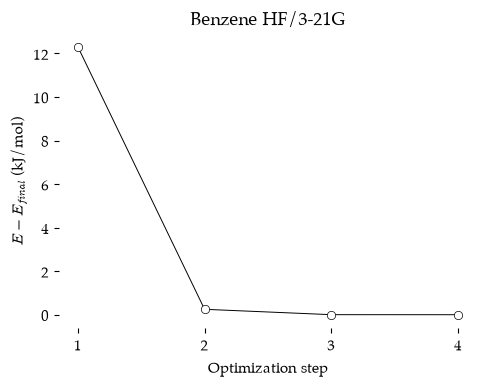

In [6]:
psi4.set_output_file("benzene_opt.out", False)

E_opt, hist_opt = psi4.optimize("hf/3-21g", molecule=benzene, return_history=True)

print(f"Final energy: {E_opt:.8f} Hartree")
print("Steps taken:", len(hist_opt["energy"]))
print(f"C1-C2 length:    {bond_length(benzene, 0, 1):.4f} Angstrom")
print(f"C1-H7 length:    {bond_length(benzene, 0, 6):.4f} Angstrom")
print(f"C1-C2-C3 angle:  {bond_angle(benzene, 0, 1, 2):.2f} degrees")
plot_history(hist_opt, "Benzene HF/3-21G")

The optimization reached &minus;229.41937162 Hartree in **4** steps. Remember that *Python* counts from **zero**: C1 is atom `0`, C2 is atom `1` and H7 is atom `6`. The C&ndash;C&ndash;C angle is exactly 120&deg;, as it must be in a regular hexagon. Because the calculation was run in *D<sub>2h</sub>*, the optimizer was actually **allowed** to make the bonds different lengths (C1&ndash;C2 and C2&ndash;C3 are not related by any *D<sub>2h</sub>* operation). Let's check that it didn't.

In [7]:
for i in range(6):
    j = (i + 1) % 6
    print(f"C{i+1}-C{j+1}: {bond_length(benzene, i, j):.6f}   C{i+1}-H{i+7}: {bond_length(benzene, i, i+6):.6f} Angstrom")

C1-C2: 1.384528   C1-H7: 1.072121 Angstrom
C2-C3: 1.384528   C2-H8: 1.072121 Angstrom
C3-C4: 1.384528   C3-H9: 1.072121 Angstrom
C4-C5: 1.384528   C4-H10: 1.072121 Angstrom
C5-C6: 1.384528   C5-H11: 1.072121 Angstrom
C6-C1: 1.384528   C6-H12: 1.072121 Angstrom


| Line | Notes |
| :---- | :---- |
| `j = (i + 1) % 6` | The next carbon around the ring. The `%` (modulo) operator gives the **remainder** after division by 6, so after carbon `5` we come back to carbon `0`. |

All six C&ndash;C bonds are the same, and so are all six C&ndash;H bonds. Benzene stayed a perfect hexagon, even though *Psi4* was only watching for *D<sub>2h</sub>* symmetry. Nothing pushed it out of *D<sub>6h</sub>*, so it stayed there.

## Evaluating the Structure

**Benzene** is a very well-studied molecule and its structure is known. Below is a table that **compares** the HF/3-21G optimized structure with the literature values {cite:p}`literatutebenzene` and with my *GAMESS* result from the previous book.

|               | *Psi4* HF/3-21G | *GAMESS* HF/3-21G | Literature |
| :----         | :-----        | :-----        | :-----     |
| C–C length	| 1.385 Å	| 1.385 Å	    | 1.397 Å    |
| C–H length	| 1.072 Å	| 1.072 Å	    | 1.084 Å    |

The HF/3-21G results were very close to the **literature** values, and the two programs agree. Now we will use these optimized coordinates in energy calculations to **experience** the benefits of symmetry.

## Expensive Calculations

We will **calculate** the energy of benzene using the HF/3-21G optimized structure. I will choose an extensive basis set and use an expensive method.

We will use the B3LYP density functional **method** and use the Dunning aug-cc-pCVTZ **basis set**. This is a correlation-consistent basis set that includes **extra** functions for the core electrons (the "C" in pCVTZ) and orbital polarization functions. The "aug" indicates the diffuse functions are also present. Let's count the atomic orbitals.

In [8]:
basis = psi4.core.BasisSet.build(benzene, "ORBITAL", "aug-cc-pcvtz")
print("Total basis functions:", basis.nbf())

for atom in [0, 6]:
    count = sum(1 for i in range(basis.nbf()) if basis.function_to_center(i) == atom)
    print(f"Basis functions on {benzene.symbol(atom)}: {count}")

Total basis functions: 564
Basis functions on C: 69
Basis functions on H: 25


| Line | Notes |
| :---- | :---- |
| `psi4.core.BasisSet.build(...)` | Builds the **basis set** for our molecule without running a calculation, so that we can look at it. |
| `basis.function_to_center(i)` | The number of the atom that basis function `i` sits on (we used this in [Chapter 6](../06-PiOrbitals/061-PiOrbitals.ipynb)). |
| `sum(1 for i in ... if ...)` | **Counts** the basis functions that sit on `atom`. |

Each carbon atom gets 69 atomic orbitals and each hydrogen gets 25. There are 564 atomic orbitals used in the **calculation** of the 564 molecular orbitals! That is exactly the number that *GAMESS* used. (In the *GAMESS* book I said 24 per hydrogen. It was 25: 6 &times; 69 + 6 &times; 25 = 564.) With *Psi4*'s usual pure (spherical) functions there would be 492.

B3LYP scales at *n*<sup>4</sup> (some other DFT methods scale at *n*<sup>3</sup>). That means that when we increase the number of orbitals (and the gaussian functions that approximate them), we increase effort enormously.

### What *GAMESS* Did

In the *GAMESS* book I performed a B3LYP/aug-cc-pCVTZ **energy calculation** using *D<sub>6h</sub>*, *C<sub>2v</sub>* (4 atom) and *C<sub>2v</sub>* (3 atom) symmetry. I **also** performed a calculation with *C<sub>1</sub>* symmetry (that means no symmetry). Below is a table of the time it took for each calculation.

| Symmetry	                | Time for B3LYP/aug-cc-pCVTZ 	| Energy                  |
| :----                     | :-----                        | :-----                  |
| *C<sub>1</sub>*	        | 71.5 minutes	                | -232.1862001924 Hartree |
| *C<sub>2v</sub>* (4 atom)	| 37.6	                        | -232.1861986292         |
| *C<sub>2v</sub>* (3 atom)	| 36.5           	            | -232.1862006973         |
| *D<sub>6h</sub>*	        | 7.6	                        | -232.1861814727         |

Wow! The *D<sub>6h</sub>* symmetry was almost five times **faster** than *C<sub>2v</sub>* and almost ten times faster than *C<sub>1</sub>*. The number of atoms in *C<sub>2v</sub>* did not make much difference. (My four-atom "*C<sub>2v</sub>*" build was actually *C<sub>2h</sub>*, but *GAMESS* ran it in the *C<sub>2v</sub>* group I asked for.) Symmetry did not change the answer, but it changed the cost.

### What *Psi4* Does

Let's run the same job in *Psi4*. We can't use *D<sub>6h</sub>*, but we can ask *Psi4* to use any **subgroup** of *D<sub>2h</sub>* with the `symmetry` keyword in the geometry. We will try *D<sub>2h</sub>*, *C<sub>2v</sub>*, *C<sub>2h</sub>* and *C<sub>1</sub>*, all from the **same** optimized coordinates, and time each one.

In [9]:
import time

benzene_opt_xyz = benzene.save_string_xyz()

timing = []
for sym in ["d2h", "c2v", "c2h", "c1"]:
    psi4.core.clean()
    mol = psi4.geometry(benzene_opt_xyz + f"symmetry {sym}\nno_reorient\n")
    psi4.set_output_file(f"benzene_b3lyp_{sym}.out", False)

    start = time.time()
    E, wfn = psi4.energy("b3lyp/aug-cc-pcvtz", molecule=mol, return_wfn=True)
    seconds = time.time() - start

    timing.append({"Method": "B3LYP/aug-cc-pCVTZ", "Symmetry": mol.schoenflies_symbol().upper(),
                   "Operations": mol.point_group().order(), "Time (s)": seconds, "Energy (Eh)": E})
    if sym == "d2h":
        wfn_big = wfn

pd.DataFrame(timing).style.format({"Time (s)": "{:.1f}", "Energy (Eh)": "{:.10f}"})

,Method,Symmetry,Operations,Time (s),Energy (Eh)
0,B3LYP/aug-cc-pCVTZ,D2H,8,17.3,-232.3417539964
1,B3LYP/aug-cc-pCVTZ,C2V,4,22.6,-232.3417539955
2,B3LYP/aug-cc-pCVTZ,C2H,4,23.1,-232.3417519605
3,B3LYP/aug-cc-pCVTZ,C1,1,23.1,-232.3417518675


| Line | Notes |
| :---- | :---- |
| `import time` | The *Python* package for reading the **clock**. |
| `benzene.save_string_xyz()` | The optimized structure as text (we met this in [Chapter 6](../06-PiOrbitals/061-PiOrbitals.ipynb)). |
| `f"symmetry {sym}\n"` | Tells *Psi4* which point group to **use**. It must be a subgroup of the real one. |
| `psi4.core.clean()` | Clears out the leftovers from the previous job before starting the next one. |
| `start = time.time()` | The time (in seconds) on the clock before the job starts. Subtracting it from the time afterwards gives the time the job took. |
| `mol.point_group().order()` | The number of **symmetry operations** in the point group: 8 for *D<sub>2h</sub>*, 4 for *C<sub>2v</sub>* and *C<sub>2h</sub>*, 1 for *C<sub>1</sub>*. |
| `timing.append({...})` | Adds a **dictionary** of results to our list. *pandas* turns a list of dictionaries into a table, one row per dictionary. |
| `wfn_big = wfn` | Keeps the *D<sub>2h</sub>* wavefunction so we can look at its orbitals later. |
| `.style.format({...})` | Shows the table with the times to one decimal place and the energies to ten. |

Well, that's **not** what we expected! The *D<sub>2h</sub>* job was a little faster (17 seconds), but the *C<sub>2v</sub>*, *C<sub>2h</sub>* and *C<sub>1</sub>* jobs all took the same time (23 seconds). That is nothing like the ten-fold difference we saw with *GAMESS*. (Your times will be different from mine. They depend on your computer.) The energies agree to within 2 &times; 10<sup>&minus;6</sup> Hartree (0.006 *kJ/mol*), so symmetry didn't change the answer here either. The tiny differences most likely come from the DFT integration grid, and they are even smaller than the differences in my *GAMESS* table (up to 2 &times; 10<sup>&minus;5</sup> Hartree). And it hardly changed the **cost**.

Also notice how **fast** this was: under a minute per job, where *GAMESS* took between 7.6 and 71.5 minutes. Some of that is a newer computer, but most of it is the **density fitting** algorithm. *Psi4* approximates the hard four-centre electron repulsion integrals with cheaper three-centre ones. The error in the energy is tiny and the savings are enormous.

So why doesn't symmetry help? The slow part of a Hartree-Fock or DFT calculation is building the Fock matrix from the electron repulsion integrals (and, for DFT, integrating the functional over a grid of points around the molecule). *Psi4* does those steps with the **atomic** orbitals, in the same way whatever the point group, and the DFT grid doesn't use symmetry either. *Psi4* uses the point group to sort the orbitals into **symmetry types** (which is still very useful, as we will see), but in our tests that saved only a little time. (I tried HF/cc-pVTZ with exact integrals, `scf_type pk`, as well. It took the same time in all four point groups too.) *GAMESS*, on the other hand, exploits the molecular symmetry "throughout almost all of the program" (that's from its documentation), including the integrals, so for *GAMESS* higher symmetry means much less work.

```{admonition} Which B3LYP? (again)
:class: dropdown
Our energies are about 0.15 Hartree lower than the *GAMESS* ones. As we saw in [Chapter 6](../06-PiOrbitals/061-PiOrbitals.ipynb), *Psi4*'s `b3lyp` and *GAMESS*'s `B3LYP` use different versions of the VWN correlation functional. Change `b3lyp` to `b3lyp5` to get the *GAMESS* version. I got &minus;232.18742049 Hartree in *D<sub>2h</sub>*, within about 0.001 Hartree of the *GAMESS* value. The small difference comes from the slightly different geometries and from density fitting.
```

### When Symmetry Does Pay Off

Symmetry matters a great deal for methods that work with **molecular** orbitals rather than atomic orbitals, like the coupled-cluster methods. Let's repeat our timing test with CCSD(T), the "gold standard" of quantum chemistry. CCSD(T) scales as *n*<sup>7</sup>, so we will use a much smaller basis set, cc-pVDZ.

In [10]:
psi4.set_options({"freeze_core": True})

for sym in ["d2h", "c2v", "c2h", "c1"]:
    psi4.core.clean()
    mol = psi4.geometry(benzene_opt_xyz + f"symmetry {sym}\nno_reorient\n")
    psi4.set_output_file(f"benzene_ccsdt_{sym}.out", False)

    start = time.time()
    E = psi4.energy("ccsd(t)/cc-pvdz", molecule=mol)
    seconds = time.time() - start

    timing.append({"Method": "CCSD(T)/cc-pVDZ", "Symmetry": mol.schoenflies_symbol().upper(),
                   "Operations": mol.point_group().order(), "Time (s)": seconds, "Energy (Eh)": E})

psi4.set_options({"freeze_core": False})
timing_table = pd.DataFrame(timing)
timing_table.style.format({"Time (s)": "{:.1f}", "Energy (Eh)": "{:.10f}"})

,Method,Symmetry,Operations,Time (s),Energy (Eh)
0,B3LYP/aug-cc-pCVTZ,D2H,8,17.3,-232.3417539964
1,B3LYP/aug-cc-pCVTZ,C2V,4,22.6,-232.3417539955
2,B3LYP/aug-cc-pCVTZ,C2H,4,23.1,-232.3417519605
3,B3LYP/aug-cc-pCVTZ,C1,1,23.1,-232.3417518675
4,CCSD(T)/cc-pVDZ,D2H,8,7.2,-231.5870886874
5,CCSD(T)/cc-pVDZ,C2V,4,9.9,-231.5870886874
6,CCSD(T)/cc-pVDZ,C2H,4,10.9,-231.5870886874
7,CCSD(T)/cc-pVDZ,C1,1,55.5,-231.5870886575


| Line | Notes |
| :---- | :---- |
| `"freeze_core": True` | Leaves the six carbon 1*s* **core** electron pairs out of the correlation treatment. They hardly take part in chemistry, and this saves a lot of time. We switch it off again afterwards. |
| `"ccsd(t)/cc-pvdz"` | Coupled-cluster with single and double excitations and a perturbative estimate of the triples, with the cc-pVDZ basis set. *Psi4* first runs a Hartree-Fock calculation and then the coupled-cluster calculation on top of it. |
| `timing_table = pd.DataFrame(timing)` | Both sets of timings, eight rows, in one table. |

There it is. The CCSD(T) job took 7.2 seconds in *D<sub>2h</sub>*, 9.9 and 10.9 seconds in the two four-operation groups and 55.5 seconds in *C<sub>1</sub>*. That is about 8 times **faster** with full *D<sub>2h</sub>* symmetry than without it. And the answer is the same: the four CCSD(T) energies agree to within 3 &times; 10<sup>&minus;8</sup> Hartree. The coupled-cluster code in *Psi4* does all of its work in blocks of orbitals sorted by symmetry type, and many blocks of the problem are **zero by symmetry** and never need to be calculated. A plot makes the difference clear.

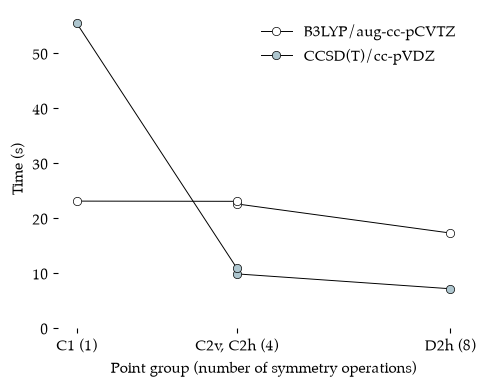

In [11]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))

colours = {"B3LYP/aug-cc-pCVTZ": "white", "CCSD(T)/cc-pVDZ": "#AEC6CF"}
for method, colour in colours.items():
    rows = timing_table[timing_table["Method"] == method]
    ax.plot(rows["Operations"], rows["Time (s)"], linewidth=0.7, color="black",
            marker="o", markerfacecolor=colour, markeredgecolor="black",
            markeredgewidth=0.5, label=method)

ax.set_xticks([1, 4, 8])
ax.set_xticklabels(["C1 (1)", "C2v, C2h (4)", "D2h (8)"])
ax.set_xlabel("Point group (number of symmetry operations)")
ax.set_ylabel("Time (s)")
ax.set_ylim(bottom=0)
ax.legend()
plt.show()

| Line | Notes |
| :---- | :---- |
| `colours = {...}` | A white fill for the first series and a pastel blue for the second, following our plotting style. |
| `timing_table[timing_table["Method"] == method]` | Picks out the **rows** for one method. |
| `ax.set_xticks(...)`, `ax.set_xticklabels(...)` | Puts tick marks only at 1, 4 and 8 operations and labels them with the point groups. |
| `ax.set_ylim(bottom=0)` | Starts the time axis at **zero** so that the differences aren't exaggerated. |

The B3LYP line is nearly flat. The CCSD(T) line falls steeply as the symmetry goes up. The lesson from the *GAMESS* book still holds, with a twist: we will always try to use the **highest** symmetry group possible when using **expensive** methods, because some programs and some methods take full advantage of it. With *Psi4* that means the correlated methods (MP2, CCSD, CCSD(T) and friends). And *Psi4* will do that for us **automatically** unless we tell it otherwise.

Let's look at the output file for the *C<sub>2v</sub>* CCSD(T) job to see how *Psi4* used the symmetry.

In [12]:
search_file("benzene_ccsdt_c2v.out", "Running in")

with open("benzene_ccsdt_c2v.out") as f:
    lines = f.readlines()

start = next(i for i, line in enumerate(lines) if "# FZDC" in line)
print("".join(lines[start:start + 6]))

    99:   Running in c2v symmetry.
	IRREP	# MOs	# FZDC	# DOCC	# SOCC	# VIRT	# FZVR
	-----	-----	------	------	------	------	------
	 A1	   35	    2	    5	    0	    28	    0
	 A2	   25	    1	    2	    0	    22	    0
	 B1	   35	    2	    4	    0	    29	    0
	 B2	   25	    1	    4	    0	    20	    0



| Line | Notes |
| :---- | :---- |
| `"# FZDC"` | The header of a little table that the coupled-cluster part of *Psi4* prints before it starts. |
| `lines[start:start + 6]` | Prints the header and the rows of the table after it. |

The table shows how *Psi4* **split** the 120 molecular orbitals into four symmetry types (`IRREP`). For each type it lists the number of MOs, the frozen core orbitals (`FZDC`, our six carbon 1*s* orbitals), the doubly occupied orbitals (`DOCC`) and the empty virtual orbitals (`VIRT`). Each symmetry type is a separate, much smaller problem. In *D<sub>2h</sub>* the split is eight ways.

## Visualization of Molecular Orbitals

Now let us look at the orbitals from the big B3LYP/aug-cc-pCVTZ calculation. We kept the *D<sub>2h</sub>* wavefunction as `wfn_big`. Benzene has 42 electrons, so 21 orbitals are doubly occupied.

Here is where symmetry earns its keep even when it doesn't save time. The ring lies in the *xy* plane, so the &pi;-orbitals are made from the *p<sub>z</sub>* atomic orbitals, which change sign when reflected through the plane of the ring. In *D<sub>2h</sub>* only four symmetry types have that property: *a<sub>u</sub>*, *b<sub>1u</sub>*, *b<sub>2g</sub>* and *b<sub>3g</sub>*. Every orbital of the other four types is a &sigma;-orbital. So we can find the &pi;-orbitals just by **filtering** the table.

In [13]:
benzene_d2h = psi4.geometry(benzene_opt_xyz + "no_reorient\n")
benzene_d2h.update_geometry()

orbitals_big = orbital_table(wfn_big, benzene_d2h)
pi_types = ["Au", "B1u", "B2g", "B3g"]

pi_big = orbitals_big[orbitals_big["Symmetry"].isin(pi_types)]
pi_big.head(12).round(4)

,MO,Symmetry,Energy (Eh),Occupied
16,17,B1u,-0.3762,yes
19,20,B3g,-0.2611,yes
20,21,B2g,-0.2611,yes
21,22,Au,-0.0160,no
22,23,B1u,-0.0160,no
28,29,B1u,0.0419,no
31,32,B2g,0.0671,no
32,33,B3g,0.0671,no
41,42,Au,0.1089,no
42,43,B1u,0.1089,no


| Line | Notes |
| :---- | :---- |
| `orbital_table(wfn_big, benzene_d2h)` | Our new tool: all 564 orbitals with their symmetry types and energies, lowest first. |
| `orbitals_big["Symmetry"].isin(pi_types)` | `True` for each row whose symmetry type is **in** our list of &pi;-types. |
| `pi_big.head(12)` | Shows only the first 12 rows. |

The three occupied &pi;-MOs are MO 17 (*b<sub>1u</sub>*, &minus;0.3762 Hartree) and the **degenerate** pair MO 20 and MO 21 (*b<sub>3g</sub>* and *b<sub>2g</sub>*, both &minus;0.2611 Hartree). These are the HOMOs. The first two empty orbitals, MOs 22 and 23 (*a<sub>u</sub>* and *b<sub>1u</sub>*, &minus;0.0160 Hartree), are the degenerate pair of LUMOs. This is the familiar Hückel pattern: one low &pi;-MO, then two pairs of degenerate MOs on either side of the non-bonding level.

```{admonition} Where did the D6h labels go?
:class: dropdown
In *D<sub>6h</sub>* the Hückel &pi;-MOs of benzene are *a<sub>2u</sub>* (&pi;<sub>1</sub>), *e<sub>1g</sub>* (&pi;<sub>2</sub>, &pi;<sub>3</sub>), *e<sub>2u</sub>* (&pi;<sub>4</sub>, &pi;<sub>5</sub>) and *b<sub>2g</sub>* (&pi;<sub>6</sub>). *D<sub>2h</sub>* has no degenerate symmetry types, so each *e* pair is **split** into two different *D<sub>2h</sub>* labels with the same energy: *e<sub>1g</sub>* becomes *b<sub>2g</sub>* + *b<sub>3g</sub>* and *e<sub>2u</sub>* becomes *a<sub>u</sub>* + *b<sub>1u</sub>*. Equal energies with different labels are the tell-tale sign of a degenerate pair in a higher symmetry.
```

But look at what happens **above** the LUMOs. The next &pi;-type orbitals come thick and fast, many of them in degenerate pairs. The molecular eigenvectors produced by the aug-cc-pCVTZ **basis set** include *f*-orbitals and diffuse functions. This **huge number** of interacting atomic orbitals gives more accurate results, but it can complicate the **images** of molecular orbitals. Where is &pi;<sub>6</sub>? Let's make **cube files** for the five &pi;-MOs that we found and one more, MO 45, the first non-degenerate *b<sub>2g</sub>* orbital above them.

In [14]:
Path("cube_big").mkdir(exist_ok=True)
psi4.set_options({"cubeprop_tasks": ["orbitals"],
                  "cubeprop_orbitals": [17, 20, 21, 22, 23, 45],
                  "cubeprop_filepath": "cube_big"})
psi4.cubeprop(wfn_big)

The file names show the energy order and then the symmetry name, as in [Chapter 6](../06-PiOrbitals/061-PiOrbitals.ipynb). Let's draw them, &pi;<sub>1</sub> first.

In [15]:
for cube_file in sorted(Path("cube_big").glob("Psi_a_*.cube")):
    print(cube_file.name)
    show_orbital(benzene_d2h, cube_file, isoval=0.03)

Psi_a_17_1-B1u.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Psi_a_20_1-B3g.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Psi_a_21_1-B2g.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

... (2 outputs left out)

Psi_a_23_2-B1u.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Psi_a_45_3-B2g.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

MO 17 (&pi;<sub>1</sub>) is a ring of electron density above the ring of carbons and another below, with no nodes other than the plane of the molecule. MOs 20 and 21 (&pi;<sub>2</sub> and &pi;<sub>3</sub>) each have **one** nodal plane perpendicular to the ring, and MOs 22 and 23 (&pi;<sub>4</sub> and &pi;<sub>5</sub>) each have **two**. Rotate them to see. These five are the textbook pictures.

MO 45 is our &pi;<sub>6</sub>. Like the Hückel &pi;<sub>6</sub>, its phase changes between **every** pair of neighbouring carbons. But it is mixed with the many extra functions of the big basis set: its lobes stretch out **past** the ring, and it is weaker near the carbons than the textbook picture. It is also far up the list of orbitals, above a crowd of other empty &pi;-type orbitals (MOs 29, 32, 33, 42 and 43 in the table above) that have no place in the Hückel picture. It does not have that "textbook" appearance.

### A Smaller Basis Set

I performed the energy calculation again using a minimal basis set (STO-3G) and had far fewer molecular orbitals to choose from. Each carbon gets just five atomic orbitals (1*s*, 2*s*, 2*p<sub>x</sub>*, 2*p<sub>y</sub>*, 2*p<sub>z</sub>*) and each hydrogen gets one, so there are only 36 molecular orbitals.

In [16]:
psi4.set_output_file("benzene_sto3g.out", False)
E_sto, wfn_sto = psi4.energy("hf/sto-3g", molecule=benzene_d2h, return_wfn=True)
print(f"HF/STO-3G energy: {E_sto:.8f} Hartree")

orbitals_sto = orbital_table(wfn_sto, benzene_d2h)
pi_sto = orbitals_sto[orbitals_sto["Symmetry"].isin(pi_types)]
pi_sto.round(4)

HF/STO-3G energy: -227.89142893 Hartree


,MO,Symmetry,Energy (Eh),Occupied
16,17,B1u,-0.4625,yes
19,20,B2g,-0.2838,yes
20,21,B3g,-0.2838,yes
21,22,Au,0.2709,no
22,23,B1u,0.2709,no
23,24,B2g,0.5101,no


Now there are exactly **six** &pi;-type orbitals, one for each carbon *p<sub>z</sub>*, just like SHMO. &pi;<sub>1</sub> is MO 17, the degenerate HOMOs are MOs 20 and 21, the degenerate LUMOs are MOs 22 and 23 and &pi;<sub>6</sub> is MO 24 (*b<sub>2g</sub>*, the *b<sub>2g</sub>* of *D<sub>6h</sub>* too). Let's draw all six.

In [17]:
Path("cube_sto").mkdir(exist_ok=True)
psi4.set_options({"cubeprop_orbitals": [17, 20, 21, 22, 23, 24],
                  "cubeprop_filepath": "cube_sto"})
psi4.cubeprop(wfn_sto)

for cube_file in sorted(Path("cube_sto").glob("Psi_a_*.cube")):
    print(cube_file.name)
    show_orbital(benzene_d2h, cube_file, isoval=0.03)

Psi_a_17_1-B1u.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Psi_a_20_1-B2g.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Psi_a_21_1-B3g.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

... (2 outputs left out)

Psi_a_23_2-B1u.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Psi_a_24_2-B2g.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Now everything looks like the textbook. &pi;<sub>1</sub> (MO 17) has no nodes across the ring, &pi;<sub>2</sub> and &pi;<sub>3</sub> (MOs 20 and 21) have one nodal plane, &pi;<sub>4</sub> and &pi;<sub>5</sub> (MOs 22 and 23) have two, and &pi;<sub>6</sub> (MO 24) has three, with the phase alternating from one carbon to the next all the way around the ring. Compare these with your SHMO pictures.

The &pi;-MOs fit much better to the **textbook** idea. Am I sticking with a comfortable lie? Should I accept the truth?

If you find it difficult to **locate** the higher level antibonding MOs in a sea of extra orbitals then try repeating the energy calculation with a smaller basis set. It will be less accurate but may give **prettier pictures**. {numref}`fig7_benzene_MOs` presents the molecular orbitals that I produced with *GAMESS* and *MacMolPlt* from the two basis sets in the previous book. Which do you prefer?

```{figure} ../../images/pi-Benzene-3.png
---
width: 500px
name: fig7_benzene_MOs
---
*&pi;-MOs for benzene from my *GAMESS* calculations. The left-hand set is from the B3LYP/aug-cc-pCVTZ energy calculation and the right-hand set is from a HF/STO-3G energy calculation. Both sets were using the same optimized HF/3-21G geometry.*
```

You can also write *Molden* files and look at the orbitals in *Avogadro*.

In [18]:
psi4.molden(wfn_big, "benzene_b3lyp_augccpcvtz.molden")
psi4.molden(wfn_sto, "benzene_sto3g.molden")

Finally, let us **save** a summary of our results as JSON files.

In [19]:
summary = pd.DataFrame({
    "Quantity": ["E HF/3-21G (Eh)", "Optimization steps", "C-C length (A)", "C-H length (A)",
                 "E HF/STO-3G (Eh)", "pi1 energy B3LYP (Eh)", "HOMO energy B3LYP (Eh)",
                 "LUMO energy B3LYP (Eh)"],
    "Value": [E_opt, len(hist_opt["energy"]), bond_length(benzene, 0, 1),
              bond_length(benzene, 0, 6), E_sto,
              pi_big["Energy (Eh)"].iloc[0], pi_big["Energy (Eh)"].iloc[1],
              pi_big["Energy (Eh)"].iloc[3]],
})

summary.to_json("benzene_HF321G.json", orient="records", indent=2)
timing_table.to_json("benzene_symmetry_timing.json", orient="records", indent=2)
summary

,Quantity,Value
0,E HF/3-21G (Eh),-229.419372
1,Optimization steps,4.000000
2,C-C length (A),1.384528
3,C-H length (A),1.072121
4,E HF/STO-3G (Eh),-227.891429
5,pi1 energy B3LYP (Eh),-0.376223
6,HOMO energy B3LYP (Eh),-0.261065
7,LUMO energy B3LYP (Eh),-0.016001


| Line | Notes |
| :---- | :---- |
| `pi_big["Energy (Eh)"].iloc[0]` | The energy in the first row of our &pi;-orbital table (&pi;<sub>1</sub>). `.iloc[1]` is the second row (a HOMO) and `.iloc[3]` the fourth (a LUMO). |
| `timing_table.to_json(...)` | Saves all eight timing runs, so we can compare them with runs on other computers. |

## Summary

We **built** benzene with a little *Python* loop that uses its six-fold symmetry, and optimized the **structure** at HF/3-21G. *Psi4* can only use **Abelian** point groups, so it ran benzene in *D<sub>2h</sub>* rather than *D<sub>6h</sub>*, but the structure stayed a perfect hexagon. We compared the calculation time for an expensive B3LYP energy calculation using different symmetries and found that, in *Psi4*, symmetry makes **little difference** to the cost of a Hartree-Fock or DFT calculation (but density fitting makes a huge one). For CCSD(T), **higher symmetry** gives much faster results. Finally we used the **symmetry labels** to pick out the &pi;-MOs from hundreds of orbitals and saw that a big basis set gives more accurate orbitals but a minimal basis set gives the **textbook** pictures.

## Exercise

After reading the above discussion, try the following.

### The Activity

Produce your **own versions** of the symmetrical treatments of benzene above. Build benzene with the `symmetry` keyword set to *D<sub>2h</sub>*, *C<sub>2v</sub>*, *C<sub>2h</sub>* and *C<sub>1</sub>*. You will have four versions of benzene structures at different symmetry. **Optimize** the structures at slightly higher theory than in this discussion (you could try HF/6-31G(d,p) or B3LYP/6-31G(d,p)). Time each optimization. Does symmetry help?

```{admonition} Hint: a lopsided start
:class: dropdown
Our optimization started from a perfect hexagon, so it had no reason to leave it. Try starting from a **distorted** ring, for example with alternating long and short C&ndash;C bonds (a "Kekulé" benzene, which is still *D<sub>3h</sub>* and runs in *C<sub>2v</sub>*). Does the optimizer find the regular hexagon again? How many steps does it take with and without symmetry?
```

```{admonition} Hint: going further
:class: dropdown
Repeat the CCSD(T) timing with the cc-pVTZ basis set, or try MP2 (`"mp2/cc-pvtz"`). Be warned: CCSD(T)/cc-pVTZ in *C<sub>1</sub>* symmetry is a **big** job for a laptop. Start with *D<sub>2h</sub>* and see how long that takes first.
```

### The Report

Report the **bond lengths** and the **times** for your calculations. Make **images** of the &pi;-MO system with *py3Dmol* or *Avogadro*. Compare it to your results from the SHMO method.

```{warning} AI Statement
:class: dropdown
This page is an adaptation of the "Benzene: MOs and Symmetry" chapter of my [previous web book on using *GAMESS*](https://blinkletter.github.io/UsingGAMESS). About **a fifth** of the text (not counting tables) is **my own work**, carried over word for word or lightly edited. This includes the introduction and most of the learning goals, the "*GAMESS* is like a cat" part of the story of building benzene, the comparison with the literature structure, the description of the basis set and the cost of B3LYP, the *GAMESS* timing table and its discussion, the discussion of the orbital pictures from large and small basis sets ("Am I sticking with a comfortable lie?"), and most of the exercise. The literature and *GAMESS* tables and the figure of the &pi;-MOs are also mine, from the previous book. The **rest of the page** was written by an **LLM system** at my request. I asked it to replace *MacMolPlt* and *GamessQ* with *Python* code for *Psi4* and *py3Dmol*. All of the *Python* code (including building benzene from its two unique atoms), the line-by-line explanations of it, the analysis of the outputs, the new material on Abelian point groups, the timing of B3LYP and CCSD(T) in *Psi4* and why they behave differently, the use of symmetry labels to find the &pi;-orbitals, the descriptions of the orbital pictures, most of the summary and the exercise hints were written by the LLM. I ran the calculations on my own computer, and the numbers quoted in the text come from those results. The two exceptions are the `b3lyp5` energy in the "Which B3LYP?" note and the HF/cc-pVTZ timing test, which come from test runs that the LLM made with *Psi4* 1.11.
```